In [1]:
import datetime
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import seaborn as sns

from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.helper_save_function import save_with_meta
from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.utils import pad_to_length, check_array_lengths
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [2]:
current_date = datetime.date.today().strftime("%Y%m%d")
print(current_date)

20261015


In [3]:
df = pd.read_pickle(f"../datasets/Processed/Averages_gChirpFieldsFiltered_20261013.pkl")
df.shape

(3784, 48)

In [4]:
df["date_field"] = df["date"].astype(str) + "_" + df["field"].astype(str)
df.shape

(3784, 49)

In [5]:
df_c1 = df[df["cond2"] == "C1"]
df_c1.shape

(1892, 49)

In [6]:
df_c1_filtered = df_c1[df_c1["qidx_gChirp"] > 0.35]
df_c1_filtered.shape

(1537, 49)

In [7]:
dates = df_c1_filtered["date"].unique()
dates

array([datetime.date(2025, 9, 8), datetime.date(2025, 10, 23),
       datetime.date(2025, 11, 19)], dtype=object)

In [8]:
counts = {}

for date in dates:

    df_date = df_c1_filtered[df_c1_filtered["date"] == date]

    counts_date = df_date["cluster_gchirp"].value_counts().sort_index()

    counts[str(date)] = counts_date

counts = pd.DataFrame(counts)
counts

,2025-09-08,2025-10-23,2025-11-19
cluster_gchirp,,,
0.0,311,74,13.0
1.0,1,109,NaN
2.0,27,56,38.0
3.0,41,351,NaN
4.0,65,17,5.0
5.0,86,37,3.0
6.0,44,67,125.0
7.0,37,27,3.0


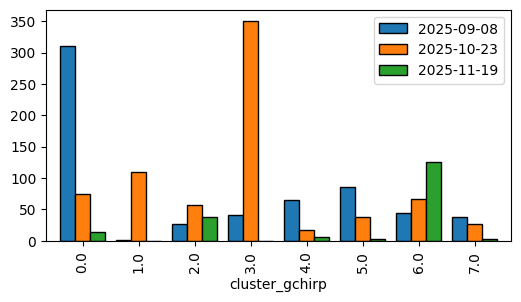

In [9]:
# Plot
ax = counts.plot(
    kind="bar",
    figsize=(6, 3),
    #color=["dodgerblue", "orange", "magenta", "green", "yellow"],
    edgecolor="black",
    width=0.8
)

plt.show()

In [10]:
cluster_ids = df_c1_filtered["cluster_gchirp"].unique()
cluster_ids = cluster_ids[~np.isnan(cluster_ids)].astype(np.int32)
cluster_ids = np.sort(cluster_ids)

n_clusters = len(cluster_ids)
print(f"N clusters: {n_clusters}")
print(cluster_ids)

N clusters: 8
[0 1 2 3 4 5 6 7]


In [11]:
counts = {}

for cluster in cluster_ids:

    df_cluster = df_c1_filtered[df_c1_filtered["cluster_gchirp"] == cluster]

    counts_cluster = df_cluster["date"].value_counts().sort_index()
    #df_date["cluster_gchirp"].value_counts().sort_index()

    counts[str(cluster)] = counts_cluster

counts = pd.DataFrame(counts)
counts

,0,1,2,3,4,5,6,7
date,,,,,,,,
2025-09-08,311,1.0,27,41.0,65,86,44,37
2025-10-23,74,109.0,56,351.0,17,37,67,27
2025-11-19,13,NaN,38,NaN,5,3,125,3


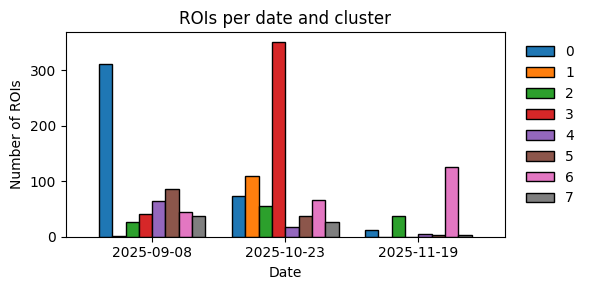

In [12]:
# Plot
ax = counts.plot(
    kind="bar",
    figsize=(6, 3),
    #color=["dodgerblue", "orange", "magenta", "green", "yellow"],
    edgecolor="black",
    width=0.8
)

ax.set_xlabel("Date")
ax.set_ylabel("Number of ROIs")
ax.set_title("ROIs per date and cluster")
ax.tick_params(axis="x", rotation=0)

# Move legend outside the plot, to the right
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

plt.tight_layout()
plt.savefig(f"../plots/clustering/n_roi_per_cluster_and_date_{current_date}.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

In [13]:
counts = {}

for cluster in cluster_ids:

    df_cluster = df_c1_filtered[df_c1_filtered["cluster_gchirp"] == cluster]

    counts_cluster = df_cluster["date_field"].value_counts().sort_index()
    #df_date["cluster_gchirp"].value_counts().sort_index()

    counts[str(cluster)] = counts_cluster

counts = pd.DataFrame(counts)
counts

,0,1,2,3,4,5,6,7
date_field,,,,,,,,
2025-09-08_XY2,2.0,NaN,NaN,NaN,58.0,1,NaN,NaN
2025-09-08_XY3,NaN,NaN,NaN,40.0,7.0,4,NaN,33.0
2025-09-08_XY7,147.0,NaN,17.0,1.0,NaN,52,26.0,3.0
2025-09-08_XY8,162.0,1.0,10.0,NaN,NaN,29,18.0,1.0
2025-10-23_XY2,6.0,NaN,33.0,NaN,2.0,4,11.0,15.0
2025-10-23_XY4,NaN,NaN,NaN,182.0,NaN,4,NaN,3.0
2025-10-23_XY5,8.0,NaN,NaN,142.0,NaN,23,NaN,4.0
2025-10-23_XY6,60.0,NaN,3.0,27.0,NaN,5,54.0,5.0
2025-10-23_XY7,NaN,109.0,20.0,NaN,15.0,1,2.0,NaN


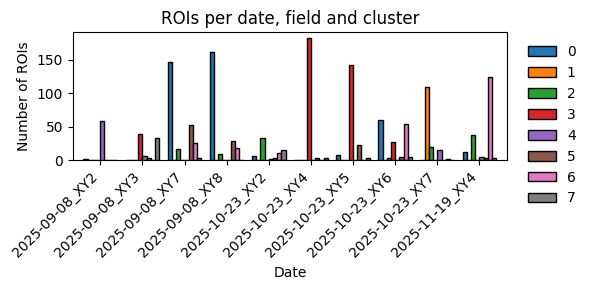

In [14]:
# Plot
ax = counts.plot(
    kind="bar",
    figsize=(6, 3),
    #color=["dodgerblue", "orange", "magenta", "green", "yellow"],
    edgecolor="black",
    width=0.8
)

ax.set_xlabel("Date")
ax.set_ylabel("Number of ROIs")
ax.set_title("ROIs per date, field and cluster")
ax.tick_params(axis="x", rotation=45)

for label in ax.get_xticklabels():
    label.set_ha("right")

# Move legend outside the plot, to the right
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

plt.tight_layout()
plt.savefig(f"../plots/clustering/n_roi_per_cluster_field_date_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

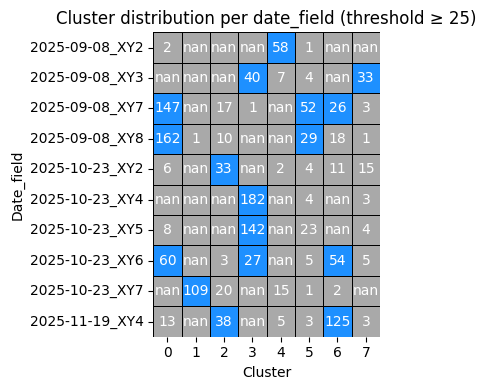

In [15]:
# Set the minimum count threshold
threshold = 25

# Binary matrix for colours: 1 = above threshold, 0 = below threshold
color_matrix = (counts >= threshold).astype(int)

# Plot heatmap
fig, ax = plt.subplots(figsize=(4, 4))

colors = ["darkgray", "dodgerblue"]

sns.heatmap(
    color_matrix,
    annot=counts,       # Show original counts as annotations
    fmt=".0f",
    cmap=colors,
    linewidths=0.5,
    linecolor="black",
    cbar=False,
    ax=ax
)

ax.set_xlabel("Cluster")
ax.set_ylabel("Date_field")
ax.set_title(f"Cluster distribution per date_field (threshold ≥ {threshold})")

plt.tight_layout()
plt.show()

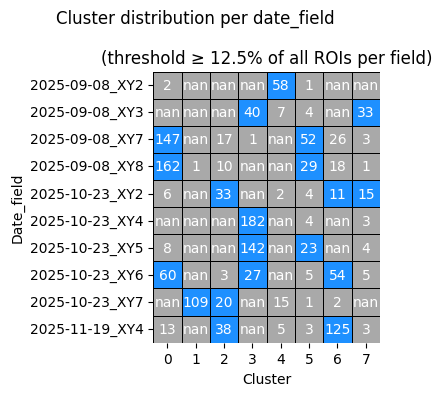

In [16]:
# Percentage threshold based on the number of clusters
threshold_pct = 100 / n_clusters

# Calculate the total number of cells for each date_field
total_cells = counts.sum(axis=1)

# Calculate the percentage of cells in each cluster per date_field
percentage_matrix = counts.div(total_cells, axis=0) * 100

# Binary matrix for colours
color_matrix = (percentage_matrix >= threshold_pct).astype(int)

# Plot heatmap
fig, ax = plt.subplots(figsize=(4, 4))

sns.heatmap(
    color_matrix,
    annot=counts,
    fmt=".0f",
    cmap=colors,
    linewidths=0.5,
    linecolor="black",
    cbar=False,
    ax=ax
)

ax.set_xlabel("Cluster")
ax.set_ylabel("Date_field")
ax.set_title(
    f"(threshold ≥ {threshold_pct:.1f}% of all ROIs per field)"
)
plt.suptitle(f"Cluster distribution per date_field")
plt.tight_layout()
plt.show()

In [17]:
# Percentage threshold based on the number of clusters
threshold_pct = 100 / n_clusters

# Calculate the total number of cells for each date_field
total_cells = counts.sum(axis=1)

# Calculate the percentage of cells in each cluster per date_field
percentage_matrix = counts.div(total_cells, axis=0) * 100

# Binary matrix for colours
above_threshold = percentage_matrix >= threshold_pct
color_matrix = above_threshold.astype(int)

# Identify clusters that exceed the threshold in only one date_field
cluster_occurrences = above_threshold.sum(axis=0)
unique_clusters = cluster_occurrences[cluster_occurrences == 1].index

# Mask for clusters above threshold in exactly one field
unique_mask = (
    above_threshold
    & percentage_matrix.columns.isin(unique_clusters)
)

# Identify date_fields where exactly one cluster exceeds the threshold
field_cluster_occurrences = above_threshold.sum(axis=1)
single_cluster_fields = field_cluster_occurrences == 1

# Mask for the cells to highlight in magenta
single_field_mask = (
    above_threshold
    & single_cluster_fields.to_numpy()[:, None]
)

/tmp/ipykernel_430797/2365552164.py:78: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(rect=[0, 0, 0.68, 0.94])


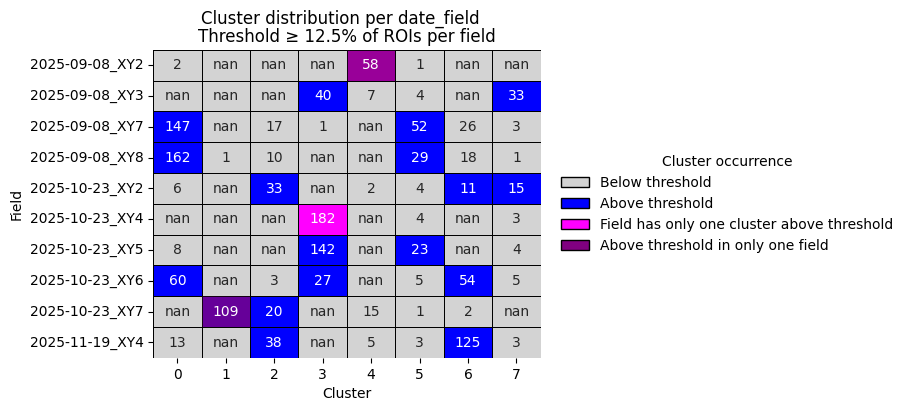

In [18]:
# Plot heatmap
fig, ax = plt.subplots(figsize=(5, 4))

# Base heatmap: below threshold = gray, above threshold = blue
sns.heatmap(
    color_matrix,
    annot=counts,
    fmt=".0f",
    cmap=sns.color_palette(["lightgray", "blue"]),
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="black",
    cbar=False,
    ax=ax
)

# Overlay magenta cells: field has exactly one cluster above threshold
sns.heatmap(
    single_field_mask.astype(int),
    mask=~single_field_mask,
    annot=False,
    cmap=sns.color_palette(["magenta"]),
    cbar=False,
    linewidths=0.5,
    linecolor="black",
    ax=ax
)

# Overlay purple cells: cluster exceeds threshold in exactly one field
sns.heatmap(
    unique_mask.astype(int),
    mask=~unique_mask,
    annot=False,
    cmap=sns.color_palette(["purple"]),
    cbar=False,
    linewidths=0.5,
    linecolor="black",
    alpha=0.8,
    ax=ax
)

# Custom legend
legend_handles = [
    mpatches.Patch(
        facecolor="lightgray", edgecolor="black",
        label="Below threshold"
    ),
    mpatches.Patch(
        facecolor="blue", edgecolor="black",
        label="Above threshold"
    ),
    mpatches.Patch(
        facecolor="magenta", edgecolor="black",
        label="Field has only one cluster above threshold"
    ),
    mpatches.Patch(
        facecolor="purple", edgecolor="black",
        label="Above threshold in only one field"
    )
]

ax.legend(
    handles=legend_handles,
    title="Cluster occurrence",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False
)

ax.set_xlabel("Cluster")
ax.set_ylabel("Field")
ax.set_title(f"Threshold ≥ {threshold_pct:.1f}% of ROIs per field")

plt.suptitle("Cluster distribution per date_field")

# Reserve space on the right for the legend
plt.tight_layout(rect=[0, 0, 0.68, 0.94])

plt.savefig(
    f"../plots/clustering/nROIs_Heatmap_ClusterAndField_{current_date}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()